# 2 Calendar features: season position and the Halloween phase

This notebook narrates branch 2 (leaves 2.1 and 2.2). It only calls functions from `src/europapark_crowd`.

Branch 2 adds two calendar feature functions to the weekday feature from the skeleton:

- `season_position`: the week of the season and the calendar days since opening day.
- `halloween`: a flag for open days in the Halloween phase.

Both use advance information only ([ADR 0001](../docs/adr/0001-advance-information-only.md)): the opening day and the Halloween dates are announced before the season starts. Terms follow [GLOSSARY.md](../GLOSSARY.md).

Data: Powered by [Queue-Times.com](https://queue-times.com/parks/51/calendar).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from europapark_crowd import features
from europapark_crowd.baselines import last_season_predictor, savvy_visitor_predictor
from europapark_crowd.evaluate import random_predictor, score
from europapark_crowd.features import halloween, season_position, weekday
from europapark_crowd.linear import linear_predictor
from europapark_crowd.open_days import load_open_days
from europapark_crowd.windows import load_windows

days = load_open_days()
windows = load_windows()
print("open summer days:", len(days))

open summer days: 1118


## Season position

The opening day is the first open day of each season. `season_position` counts calendar days from it, so a closure inside the season still counts. The opening day is day 0 and falls in week 1.

Every opening day is a Saturday, so the weeks of the season run Saturday to Friday. Summer 2019 opened latest, on 6 April. The 18–22 March 2024 closure does not move the 2024 opening day.

In [2]:
position = pd.concat([days, season_position(days)], axis=1)
position.groupby("season").agg(
    opening_day=("date", "min"),
    last_day=("date", "max"),
    last_week=("week_of_season", "max"),
).assign(opening_weekday=lambda t: t["opening_day"].dt.day_name())

,opening_day,last_day,last_week,opening_weekday
season,,,,
summer 2019,2019-04-06,2019-11-03,31,Saturday
summer 2022,2022-03-26,2022-11-06,33,Saturday
summer 2023,2023-03-25,2023-11-05,33,Saturday
summer 2024,2024-03-16,2024-11-03,34,Saturday
summer 2025,2025-03-22,2025-11-02,33,Saturday


The mean crowd level by week of the season is not a straight line. It peaks around the Easter holidays (weeks 3–4), the summer holidays (weeks 20–21) and Halloween (week 32). It dips at the very start, just after Easter and in early autumn.

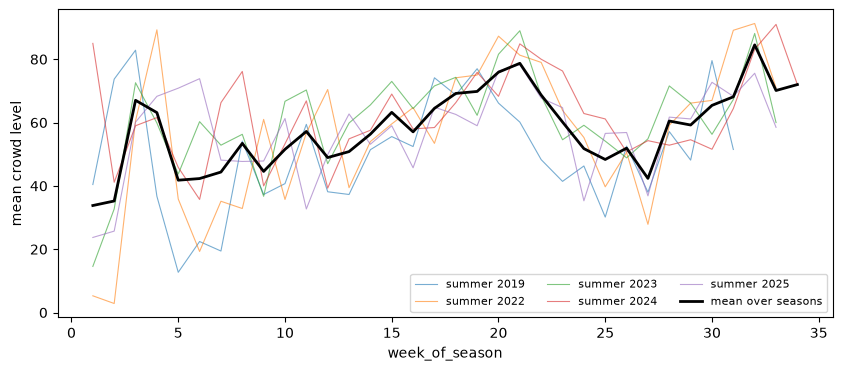

In [3]:
weekly = position.pivot_table(index="week_of_season", columns="season", values="crowd_level", aggfunc="mean")
ax = weekly.plot(figsize=(10, 4), lw=0.8, alpha=0.6)
weekly.mean(axis=1).plot(ax=ax, color="black", lw=2, label="mean over seasons")
ax.set_ylabel("mean crowd level")
ax.legend(ncols=3, fontsize=8);

The ridge model gets both columns as plain numbers, so it can only fit a straight-line trend through these peaks. Nonlinear use waits for the tuned linear model (4.2) and LightGBM (4.3).

## The Halloween phase

`halloween` flags the 37 days ending on the last day of the summer season, the first Sunday of November. The flag comes from this date rule, because 2019 pages carry no season label. Each season gets one uninterrupted run of 37 flagged open days.

In [4]:
flagged = pd.concat([days, halloween(days)], axis=1)
flagged[flagged["halloween"] == 1].groupby("season")["date"].agg(first="min", last="max", days="count")

,first,last,days
season,,,
summer 2019,2019-09-28,2019-11-03,37
summer 2022,2022-10-01,2022-11-06,37
summer 2023,2023-09-30,2023-11-05,37
summer 2024,2024-09-28,2024-11-03,37
summer 2025,2025-09-27,2025-11-02,37


On the labelled seasons 2022–2025 the flag matches the Halloween label on every day. The 2019 rows have no label, and the 2019 start (28 September) is still unverified against an official source.

In [5]:
pd.crosstab(flagged["season_label"].fillna("no label (2019)"), flagged["halloween"])

halloween,0,1
season_label,,
Halloween,0,148
Summer Season,758,0
no label (2019),175,37


The Halloween phase is busier than the rest of the season on every weekday. Most weekdays rise by 11–15 points, but Tuesday rises by less than 1 point.

,rest of season,Halloween phase
date,,
Monday,56.2,68.0
Tuesday,53.1,53.9
Wednesday,49.3,61.0
Thursday,52.3,63.4
Friday,46.4,61.2
Saturday,72.4,87.7
Sunday,56.9,69.2


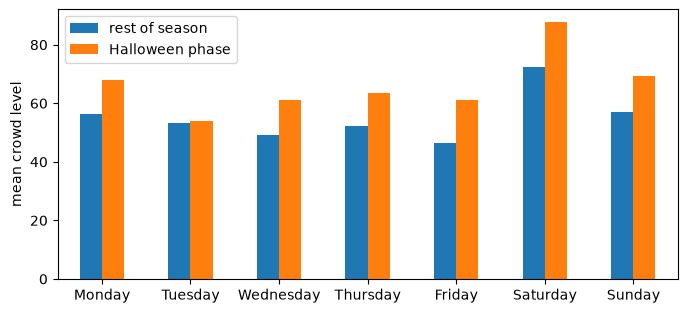

In [6]:
inside = flagged.pivot_table(
    index=flagged["date"].dt.day_name(), columns="halloween", values="crowd_level", aggfunc="mean"
).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
inside.columns = ["rest of season", "Halloween phase"]
inside.plot.bar(figsize=(8, 3.5), ylabel="mean crowd level", xlabel="", rot=0)
inside.round(1)

## Score changes

The linear model reads the module-level feature list `features.FEATURES`. To compare feature sets, this notebook sets the list to each set in turn and restores it afterwards. `linear.py` stays unchanged.

The four sets are weekday only (the skeleton model), weekday plus season position, weekday plus Halloween, and all three features.

In [7]:
feature_sets = {
    "weekday": [weekday],
    "weekday + season position": [weekday, season_position],
    "weekday + halloween": [weekday, halloween],
    "all three": [weekday, season_position, halloween],
}
full_list = features.FEATURES
linear = {}
for name, feature_list in feature_sets.items():
    features.FEATURES = feature_list
    linear[f"linear ({name})"] = score(linear_predictor, days, windows)
features.FEATURES = full_list

baselines = {
    "random": score(random_predictor, days, windows),
    "savvy visitor": score(savvy_visitor_predictor, days, windows),
    "last season": score(last_season_predictor, days, windows),
}
results = pd.concat(baselines | linear, names=["model"])
results.round(3)

season  days  \
model                              run   stage                         
random                             run 1 validate  summer 2023   226   
                                         test      summer 2024   228   
                                   run 2 validate  summer 2024   228   
                                         test      summer 2025   226   
savvy visitor                      run 1 validate  summer 2023   226   
                                         test      summer 2024   228   
                                   run 2 validate  summer 2024   228   
                                         test      summer 2025   226   
last season                        run 1 validate  summer 2023   226   
                                         test      summer 2024   228   
                                   run 2 validate  summer 2024   228   
                                         test      summer 2025   226   
linear (weekday)                   run 1 validate  summer 2023   226   
                                         test      summer 2024   228   
                                   run 2 validate  summer 2024   228   
                                         test      summer 2025   226   
linear (weekday + season position) run 1 validate  summer 2023   226   
                                         test      summer 2024   228   
                                   run 2 validate  summer 2024   228   
                                         test      summer 2025   226   
linear (weekday + halloween)       run 1 validate  summer 2023   226   
                                         test      summer 2024   228   
                                   run 2 validate  summer 2024   228   
                                         test      summer 2025   226   
linear (all three)                 run 1 validate  summer 2023   226   
                                         test      summer 2024   228   
                                   run 2 validate  summer 2024   228   
                                         test      summer 2025   226   

                                                   precision  spearman  regret  
model                              run   stage                                  
random                             run 1 validate      0.339    -0.033  32.312  
                                         test          0.298     0.045  15.000  
                                   run 2 validate      0.298     0.045  15.000  
                                         test          0.339     0.006  35.059  
savvy visitor                      run 1 validate      0.429     0.450  26.038  
                                         test          0.368     0.355  28.454  
                                   run 2 validate      0.368     0.355  28.454  
                                         test          0.429     0.352  23.816  
last season                        run 1 validate      0.625     0.515  14.891  
                                         test          0.386     0.404  23.294  
                                   run 2 validate      0.386     0.404  23.294  
                                         test          0.429     0.435  19.059  
linear (weekday)                   run 1 validate      0.339     0.334  25.899  
                                         test          0.351     0.258  27.398  
                                   run 2 validate      0.351     0.258  27.398  
                                         test          0.286     0.204  22.153  
linear (weekday + season position) run 1 validate      0.464     0.414  17.562  
                                         test          0.509     0.367  21.647  
                                   run 2 validate      0.509     0.367  21.647  
                                         test          0.464     0.305   8.000  
linear (weekday + halloween)       run 1 validate      0.357     0.345  25.427  
                                

Run 1 test and run 2 validation both fit on 2019, 2022 and 2023 and score 2024, so their rows match exactly.

The change each feature makes on top of the model without it, per run and stage:

In [8]:
metrics = ["precision", "spearman", "regret"]
comparisons = {
    "season position, over weekday": ("weekday + season position", "weekday"),
    "halloween, over weekday": ("weekday + halloween", "weekday"),
    "halloween, over weekday + season position": ("all three", "weekday + season position"),
}
changes = pd.concat(
    {
        name: linear[f"linear ({with_it})"][metrics] - linear[f"linear ({without})"][metrics]
        for name, (with_it, without) in comparisons.items()
    },
    names=["change"],
)
changes.round(3)

precision  spearman  \
change                                    run   stage                           
season position, over weekday             run 1 validate      0.125     0.080   
                                                test          0.158     0.109   
                                          run 2 validate      0.158     0.109   
                                                test          0.179     0.101   
halloween, over weekday                   run 1 validate      0.018     0.012   
                                                test          0.000     0.044   
                                          run 2 validate      0.000     0.044   
                                                test          0.036     0.068   
halloween, over weekday + season position run 1 validate      0.018    -0.000   
                                                test         -0.018    -0.001   
                                          run 2 validate     -0.018    -0.001   
                                                test          0.000    -0.003   

                                                          regret  
change                                    run   stage             
season position, over weekday             run 1 validate  -8.337  
                                                test      -5.751  
                                          run 2 validate  -5.751  
                                                test     -14.153  
halloween, over weekday                   run 1 validate  -0.472  
                                                test      -0.343  
                                          run 2 validate  -0.343  
                                                test      -0.912  
halloween, over weekday + season position run 1 validate   0.000  
                                                test       0.000  
                                          run 2 validate   0.000  
                                                test       0.000

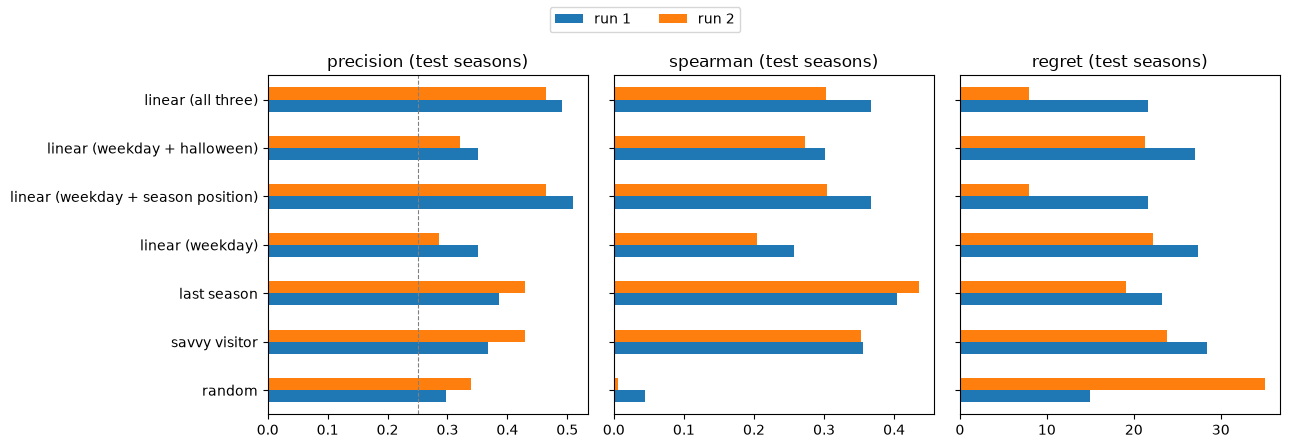

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
test = results.xs("test", level="stage")
for ax, metric in zip(axes, ["precision", "spearman", "regret"]):
    test[metric].unstack("run").plot.barh(ax=ax, legend=False)
    ax.set_title(f"{metric} (test seasons)")
    ax.set_ylabel("")
axes[0].axvline(0.25, color="grey", ls="--", lw=0.8)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.92))

## Takeaway

- Season position does the real work. Even as a straight-line trend, it lifts quiet-day precision from chance level to 0.46–0.51, raises Spearman by 0.08–0.11 and cuts regret by 6–14 points.
- On its own, the Halloween flag helps the weekday model a little: Spearman rises by 0.01–0.07.
- On top of season position, the Halloween flag adds almost nothing. Precision moves by at most 0.02, Spearman by at most 0.003, and regret does not change. A straight-line trend in days since opening already rises towards the season end, so it absorbs most of the Halloween lift.
- The full calendar model now beats the last-season baseline on precision and regret in both test seasons. It still trails it on Spearman and on every metric for the 2023 validation season.
- The next branch adds holiday pressure, which should explain the Easter and summer-holiday peaks that a straight line cannot fit.